In [ ]:
import warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.cloud import bigquery
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})


In [ ]:
from google.colab import auth
auth.authenticate_user()

client = bigquery.Client("orbital-nuance-507422-g1")

In [ ]:
MONTHLY_SQL = """
SELECT
    DATE_TRUNC(DATE(created_at), MONTH)  AS month,
    ROUND(SUM(sale_price), 2)            AS revenue,
    COUNT(DISTINCT order_id)             AS orders,
    COUNT(DISTINCT user_id)              AS customers
FROM `bigquery-public-data.thelook_ecommerce.order_items`
WHERE status NOT IN ('Cancelled', 'Returned')
  AND created_at < TIMESTAMP(DATE_TRUNC(CURRENT_DATE(), MONTH))
GROUP BY month
ORDER BY month
"""

monthly = client.query(MONTHLY_SQL).to_dataframe()
monthly["month"] = pd.to_datetime(monthly["month"])
monthly = monthly.set_index("month").asfreq("MS")   # enforces a regular monthly index

monthly["aov"] = monthly["revenue"] / monthly["orders"]   # average order value
print(monthly.isna().sum().sum(), "missing values")
monthly.head()

0 missing values


,revenue,orders,customers,aov
month,,,,
2019-01-01,540.76,6,6,90.126667
2019-02-01,1104.68,18,18,61.371111
2019-03-01,1879.49,25,25,75.1796
2019-04-01,2826.52,40,40,70.663
2019-05-01,4339.94,53,52,81.88566


###Ramp-up period trim
The first months of the dataset have very little activity (the business is just launching). Including them makes the model learn a growth curve that isn't representative of the current business, so I drop months below 5% of median revenue.

In [ ]:
threshold = 0.05 * monthly["revenue"].median()
monthly = monthly[monthly["revenue"] >= threshold]
print(f"Using {len(monthly)} months: {monthly.index.min():%b %Y} to {monthly.index.max():%b %Y}")
revenue = monthly["revenue"]
print(f"Total revenue: ${revenue.sum():,.0f}")

Using 89 months: May 2019 to Sep 2026
Total revenue: $7,602,701


## 3. Exploratory analysis

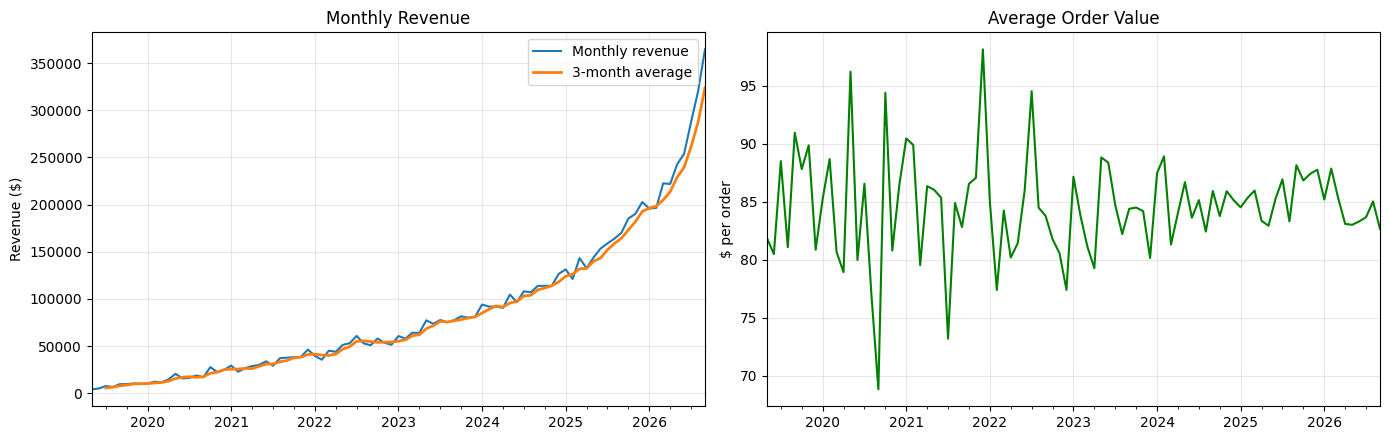

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

revenue.plot(ax=axes[0], label="Monthly revenue")
revenue.rolling(3).mean().plot(ax=axes[0], label="3-month average", linewidth=2)
axes[0].set(title="Monthly Revenue", xlabel="", ylabel="Revenue ($)")
axes[0].legend()

monthly["aov"].plot(ax=axes[1], color="green")
axes[1].set(title="Average Order Value", xlabel="", ylabel="$ per order")

plt.tight_layout(); plt.show()

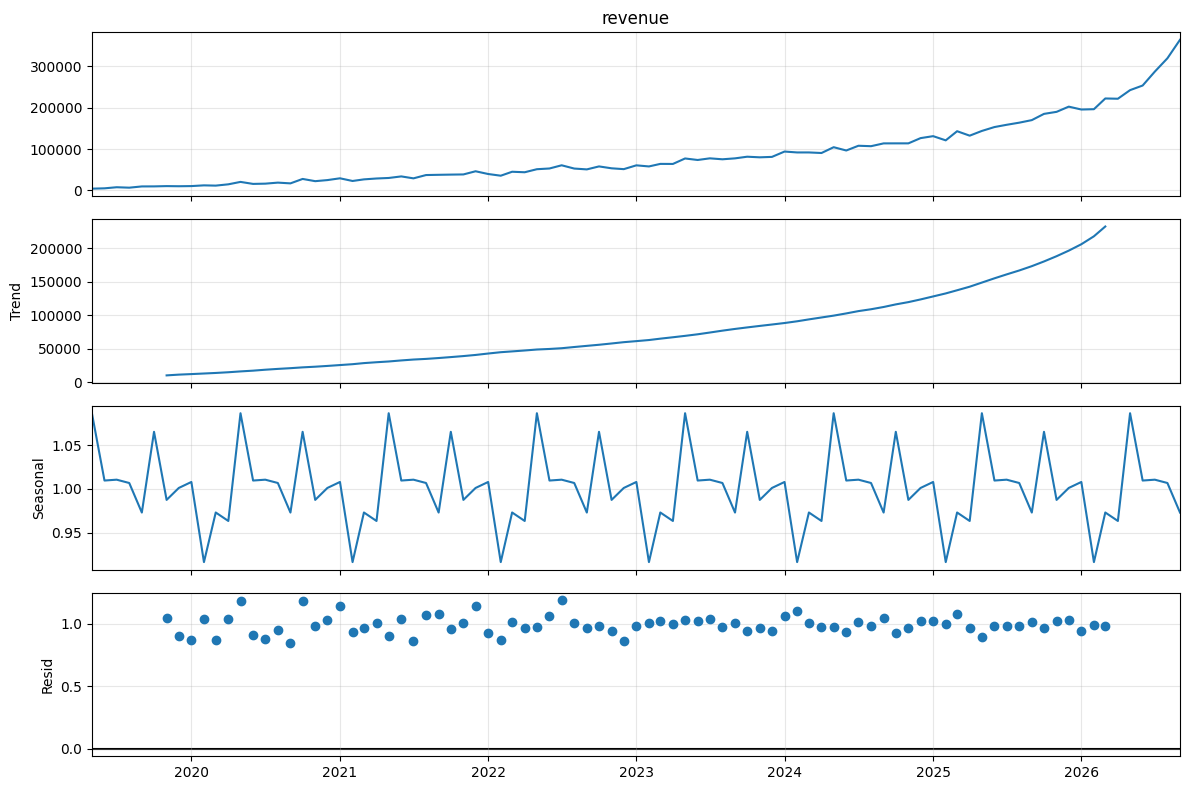

Strongest month: 5 (1.09x typical)
Weakest month:   2 (0.92x typical)


In [ ]:
# Trend / seasonality / residual split (2 Yr Gap)
decomp = seasonal_decompose(revenue, model="multiplicative", period=12)
fig = decomp.plot(); fig.set_size_inches(12, 8); plt.tight_layout(); plt.show()

seasonal_profile = decomp.seasonal.groupby(decomp.seasonal.index.month).mean()
print("Strongest month:", seasonal_profile.idxmax(), f"({seasonal_profile.max():.2f}x typical)")
print("Weakest month:  ", seasonal_profile.idxmin(), f"({seasonal_profile.min():.2f}x typical)")

**Importance:** if the seasonal component is clearly non-flat, plain ARIMA(1,1,1) cannot capture it. That motivates **SARIMA**, which adds seasonal terms.

## 4. Stationarity
ARIMA needs a stationary series. I use a **log transform** (stabilises variance when growth is multiplicative) and then test how much differencing is required with the ADF test (H0: series is non-stationary).

In [ ]:
log_rev = np.log(revenue)

def adf_report(series, name):
    stat, p, *_ = adfuller(series.dropna())
    verdict = "stationary" if p < 0.05 else "NON-stationary"
    print(f"{name:<28} ADF={stat:7.3f}  p={p:.4f}  -> {verdict}")

adf_report(log_rev,                    "log revenue")
adf_report(log_rev.diff(),             "log revenue, d=1")
adf_report(log_rev.diff().diff(12),    "log revenue, d=1 + seasonal D=1")

log revenue                  ADF= -1.819  p=0.3711  -> NON-stationary
log revenue, d=1             ADF=-10.501  p=0.0000  -> stationary
log revenue, d=1 + seasonal D=1 ADF= -0.966  p=0.7653  -> NON-stationary


Pick `d` and `D` from the first row that comes back stationary. The search below fixes `d=1, D=1`, which is the usual outcome for trending, seasonal monthly sales.

## 5. Model selection
Instead of guessing `(1,1,1)`, I search a small grid and rank by **AIC** . The search uses only the **training** window so the test set stays untouched.

In [ ]:
HOLDOUT = 12
train_log = log_rev.iloc[:-HOLDOUT]
test      = revenue.iloc[-HOLDOUT:]

d, D, s = 1, 0, 12
rows = []
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        fit = SARIMAX(train_log, order=(p, d, q), seasonal_order=(P, D, Q, s),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        rows.append({"order": (p, d, q), "seasonal": (P, D, Q, s), "aic": fit.aic})
    except Exception:
        continue



search = pd.DataFrame(rows).sort_values("aic").reset_index(drop=True)
best = search.iloc[0]
print("Top 5 candidates:")
display(search.head())
best_order, best_seasonal = best["order"], best["seasonal"]

Top 5 candidates:


,order,seasonal,aic
0,"(1, 1, 2)","(0, 0, 0, 12)",-123.698804
1,"(2, 1, 2)","(0, 0, 0, 12)",-121.973413
2,"(2, 1, 0)","(1, 0, 1, 12)",-104.436945
3,"(1, 1, 2)","(1, 0, 0, 12)",-103.711933
4,"(2, 1, 2)","(1, 0, 0, 12)",-103.560360


## 6. Backtest against baselines
A forecast model is only useful if it beats simple alternatives. I compare four approaches on the **12 held-out months**:

| Model | Idea |
|---|---|
| Naive | Next 12 months = last observed month |
| Seasonal naive | Each month = same month last year |
| ARIMA(1,1,1) | The original baseline model |
| SARIMA (tuned) | Orders picked by AIC above |

In [ ]:
def metrics(actual, pred):
    return {
        "MAE":  mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE %": (np.abs((actual - pred) / actual)).mean() * 100,
    }

train = revenue.iloc[:-HOLDOUT]
preds = {}

preds["Naive"] = pd.Series(train.iloc[-1], index=test.index)
preds["Seasonal naive"] = pd.Series(train.iloc[-12:].values, index=test.index)

arima_fit = ARIMA(train_log, order=(1, 1, 1)).fit()
preds["ARIMA(1,1,1)"] = np.exp(arima_fit.forecast(HOLDOUT)).set_axis(test.index)

sarima_fit = SARIMAX(train_log, order=best_order, seasonal_order=best_seasonal,
                     enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sarima_fc = sarima_fit.get_forecast(HOLDOUT)
preds["SARIMA (tuned)"] = np.exp(sarima_fc.predicted_mean).set_axis(test.index)

sarima_D1 = SARIMAX(train_log, order=best_order, seasonal_order=(1, 1, 1, 12),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
preds["SARIMA (D=1 check)"] = np.exp(sarima_D1.forecast(HOLDOUT)).set_axis(test.index)

hw_fit = ExponentialSmoothing(
    train,                      # raw revenue, not logged
    trend="add",
    damped_trend=True,
    seasonal="mul",
    seasonal_periods=12,
).fit()
preds["Holt-Winters"] = hw_fit.forecast(HOLDOUT).set_axis(test.index)

scores = pd.DataFrame({name: metrics(test, p) for name, p in preds.items()}).T.round(2)
scores = scores.sort_values("MAPE %")
display(scores)
print("Best model on holdout:", scores.index[0])

,MAE,RMSE,MAPE %
SARIMA (tuned),18038.58,32156.23,6.01
SARIMA (D=1 check),31655.05,43764.84,11.50
Holt-Winters,43428.92,57054.17,16.03
Naive,70113.70,88811.69,25.99
"ARIMA(1,1,1)",71505.20,89896.32,26.60
Seasonal naive,100826.73,107702.52,40.86


Best model on holdout: SARIMA (tuned)


In [ ]:
candidates = {
    "SARIMA D=1 (2,1,2)(0,1,1,12)": ((2, 1, 2), (0, 1, 1, 12)),
    "SARIMA D=1 (1,1,2)(1,1,1,12)": ((1, 1, 2), (1, 1, 1, 12)),
    "ARIMA D=0 (1,1,2)":            ((1, 1, 2), (0, 0, 0, 12)),
}

n, horizon = len(log_rev), 6
origins = [n - 30, n - 24, n - 18, n - 12, n - 6]   # 5 forecast windows
rows = []

for name, (order, seasonal) in candidates.items():
    for end in origins:
        tr = log_rev.iloc[:end]
        te = revenue.iloc[end:end + horizon]
        fit = SARIMAX(tr, order=order, seasonal_order=seasonal,
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        pred = np.exp(fit.forecast(horizon)).set_axis(te.index)
        rows.append({"model": name, "origin": revenue.index[end - 1].strftime("%b %Y"),
                     "MAPE %": (np.abs((te - pred) / te)).mean() * 100})

rolling = pd.DataFrame(rows)
display(rolling.pivot(index="model", columns="origin", values="MAPE %").round(1))
print(rolling.groupby("model")["MAPE %"].mean().round(1).sort_values())

origin,Mar 2024,Mar 2025,Mar 2026,Sep 2024,Sep 2025
model,,,,,
"ARIMA D=0 (1,1,2)",9.2,6.2,11.3,4.5,11.1
"SARIMA D=1 (1,1,2)(1,1,1,12)",8.0,3.8,12.8,4.4,7.0
"SARIMA D=1 (2,1,2)(0,1,1,12)",8.8,11.6,9.2,3.3,2.2


model
SARIMA D=1 (2,1,2)(0,1,1,12)    7.0
SARIMA D=1 (1,1,2)(1,1,1,12)    7.2
ARIMA D=0 (1,1,2)               8.5
Name: MAPE %, dtype: float64


In [ ]:
best_order, best_seasonal = (2, 1, 2), (0, 1, 1, 12)

I selected the model in three stages. ADF tests showed one regular difference was needed (p < 0.001) while seasonal differencing was inconclusive (p = 0.77), so I compared both options. AIC can’t compare models with different differencing, so I judged them on out-of-sample error instead: a 12-month holdout and a rolling-origin backtest across five 6-month windows. A SARIMA(2,1,2)(0,1,1,12) had the lowest average error (7.0% MAPE), narrowly ahead of a second seasonal specification (7.2%) and a non-seasonal ARIMA (8.5%). Performance varied by window, so I report forecasts with 95% intervals rather than point estimates alone.

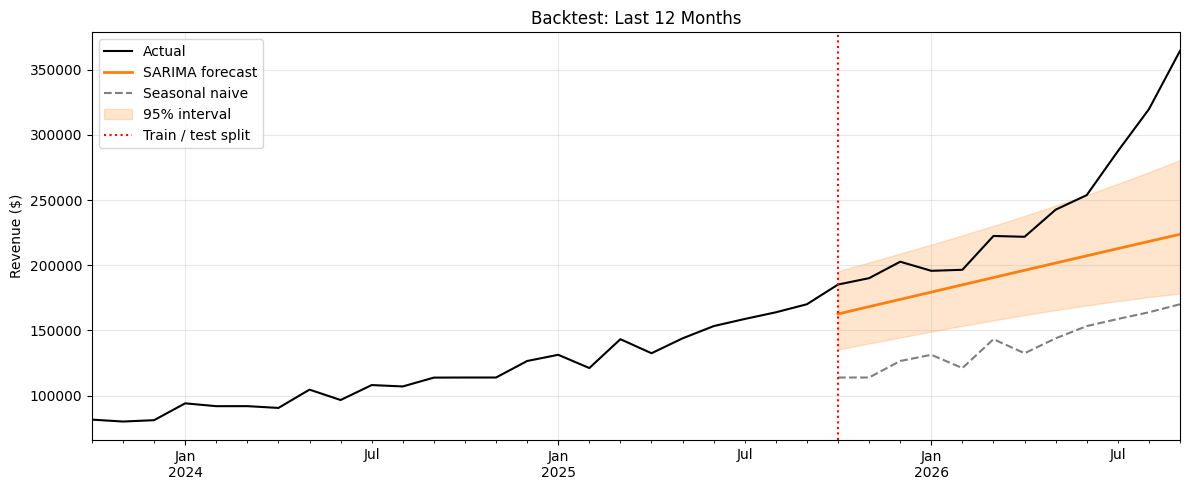

In [ ]:
ci = np.exp(sarima_fc.conf_int(alpha=0.05)).set_axis(test.index)

fig, ax = plt.subplots()
revenue.iloc[-36:].plot(ax=ax, label="Actual", color="black")
preds["SARIMA (tuned)"].plot(ax=ax, label="SARIMA forecast", color="tab:orange", linewidth=2)
preds["Seasonal naive"].plot(ax=ax, label="Seasonal naive", color="tab:gray", linestyle="--")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="tab:orange", alpha=0.2, label="95% interval")
ax.axvline(test.index[0], color="red", linestyle=":", label="Train / test split")
ax.set(title="Backtest: Last 12 Months", xlabel="", ylabel="Revenue ($)")
ax.legend(); plt.tight_layout(); plt.show()

## 7. Residual diagnostics
A good model leaves residuals that look like random noise. The **Ljung-Box test** checks for leftover autocorrelation (p > 0.05 is what we want).

Ljung-Box p-value (lag 12): 0.137 -> no significant autocorrelation


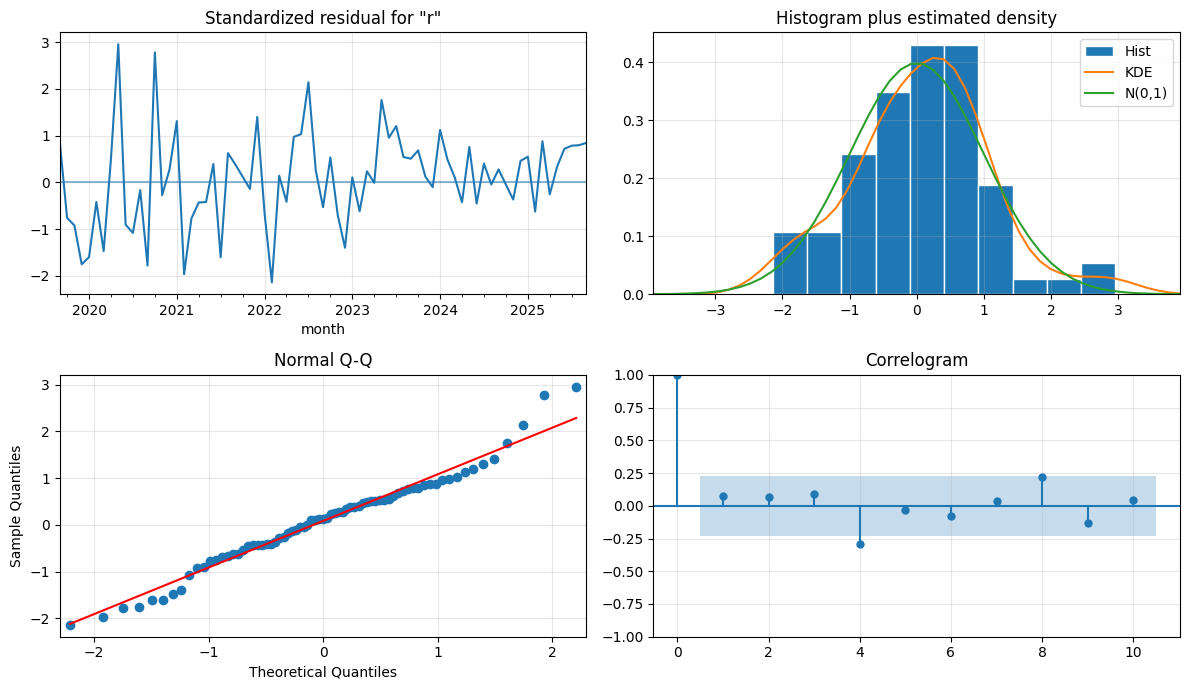

In [ ]:
    resid = sarima_fit.resid.iloc[s + d:]   # drop warm-up observations
lb = acorr_ljungbox(resid, lags=[12], return_df=True)
print(f"Ljung-Box p-value (lag 12): {lb['lb_pvalue'].iloc[0]:.3f}",
      "-> no significant autocorrelation" if lb["lb_pvalue"].iloc[0] > 0.05 else "-> residual structure remains")

sarima_fit.plot_diagnostics(figsize=(12, 7)); plt.tight_layout(); plt.show()

## 8. Final forecast
After validating, I **refit on all available data** and forecast the next 12 months with 95% prediction intervals.

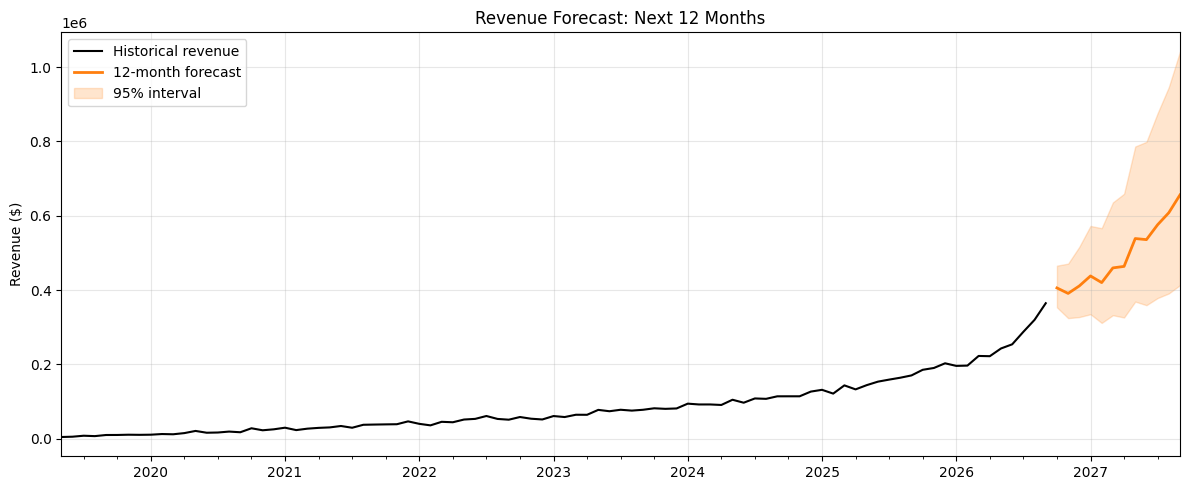

,forecast,lower_95,upper_95
2026-10-01,405588.0,353380.0,465508.0
2026-11-01,390851.0,324334.0,471011.0
2026-12-01,410979.0,327191.0,516225.0
2027-01-01,437826.0,334868.0,572440.0
2027-02-01,419978.0,311384.0,566442.0
2027-03-01,459519.0,332167.0,635698.0
2027-04-01,463563.0,326065.0,659044.0
2027-05-01,538526.0,368837.0,786284.0
2027-06-01,535625.0,359163.0,798784.0
2027-07-01,575718.0,378362.0,876016.0


In [ ]:
FUTURE = 12
final_fit = SARIMAX(log_rev, order=best_order, seasonal_order=best_seasonal,
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

fc = final_fit.get_forecast(FUTURE)
future_idx = pd.date_range(revenue.index[-1] + pd.offsets.MonthBegin(1), periods=FUTURE, freq="MS")

forecast_df = pd.DataFrame({
    "forecast": np.exp(fc.predicted_mean.values),
    "lower_95": np.exp(fc.conf_int().iloc[:, 0].values),
    "upper_95": np.exp(fc.conf_int().iloc[:, 1].values),
}, index=future_idx).round(0)

fig, ax = plt.subplots()
revenue.plot(ax=ax, label="Historical revenue", color="black")
forecast_df["forecast"].plot(ax=ax, label="12-month forecast", color="tab:orange", linewidth=2)
ax.fill_between(forecast_df.index, forecast_df["lower_95"], forecast_df["upper_95"],
                color="tab:orange", alpha=0.2, label="95% interval")
ax.set(title="Revenue Forecast: Next 12 Months", xlabel="", ylabel="Revenue ($)")
ax.legend(); plt.tight_layout(); plt.show()

forecast_df

he final SARIMA(2,1,2)(0,1,1,12) model projects revenue of about $1.2M for Q4 2026 (95% range roughly $1.0M-$1.45M), rising to roughly $5.9M over the next 12 months if recent growth persists. Backtest error averaged 7% MAPE over 6-month windows, so near-term forecasts are the most reliable; the interval widens to roughly -37%/+59% by month 12. The data is synthetic and excludes promotions, so these figures illustrate the method rather than predict a real business.

## 9. Business takeaways (computed, not hand-typed)

In [ ]:
FINAL_MODEL = "SARIMA(2,1,2)(0,1,1,12)"
ROLLING_MAPE = 7.0   # mean MAPE across five 6-month windows

last12 = revenue.iloc[-12:].sum()
prev12 = revenue.iloc[-24:-12].sum()
next12 = forecast_df["forecast"].sum()

print("Last 6 months of actual revenue:")
print(revenue.tail(6).round(0).to_string(), "\n")

print(f"Prior 12-month revenue:     ${prev12:,.0f}")
print(f"Trailing 12-month revenue:  ${last12:,.0f}  ({(last12/prev12-1)*100:+.1f}% YoY)")
print(f"Forecast next 12 months:    ${next12:,.0f}  ({(next12/last12-1)*100:+.1f}% YoY)")
print(f"Forecast Q4 2026:           ${forecast_df['forecast'].iloc[:3].sum():,.0f}")
print(f"Seasonal pattern:           strongest month {seasonal_profile.idxmax()}, weakest {seasonal_profile.idxmin()}")
print(f"{FINAL_MODEL} rolling-backtest MAPE: {ROLLING_MAPE}%")

coverage = ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).mean() * 100
print(f"Backtest interval coverage: {coverage:.0f}% (target ~95%)")

Last 6 months of actual revenue:
month
2026-04-01    221864.0
2026-05-01    242660.0
2026-06-01    253831.0
2026-07-01    287497.0
2026-08-01    319732.0
2026-09-01    364483.0
Freq: MS 

Prior 12-month revenue:     $1,673,091
Trailing 12-month revenue:  $2,883,012  (+72.3% YoY)
Forecast next 12 months:    $5,902,243  (+104.7% YoY)
Forecast Q4 2026:           $1,207,418
Seasonal pattern:           strongest month 5, weakest 2
SARIMA(2,1,2)(0,1,1,12) rolling-backtest MAPE: 7.0%
Backtest interval coverage: 75% (target ~95%)


### Revenue Forecasting & Business Performance Analysis

**Objective:** Analyze historical revenue trends, measure year-over-year growth, identify seasonal patterns, and forecast future business performance using time-series modeling.

**Key Findings**

- **Strong revenue growth:** Trailing 12-month revenue reached \$2.88 million, a 72.3% increase over the previous 12-month period.
- **Consistent recent performance:** Monthly revenue increased from \$221,864 in April 2026 to \$364,483 in September 2026, representing 64.3% growth across the period.
- **Forward-looking projections:** The SARIMA model forecasts approximately \$1.21 million in revenue for Q4 2026 and \$5.90 million over the following 12 months.
- **Seasonal patterns:** The model identifies May as the strongest month and February as the weakest, providing a starting point for investigating seasonal demand and planning inventory or marketing efforts.
- **Model evaluation:** Rolling backtesting produced a 7.0% mean absolute percentage error (MAPE). However, prediction interval coverage was 75%, below the approximate 95% target, indicating that uncertainty estimates require further evaluation.

**Business Impact**

This analysis demonstrates how historical sales data can support revenue monitoring, demand forecasting, and business planning. The results provide a foundation for evaluating seasonal opportunities, allocating resources, and preparing for potential changes in future sales.

**Tools & Techniques:** Python, pandas, time-series analysis, SARIMA forecasting, rolling backtesting, MAPE evaluation, and revenue visualization.

## 10. Where the revenue comes from (SQL → Python)
Context for the forecast: which categories drive the totals.

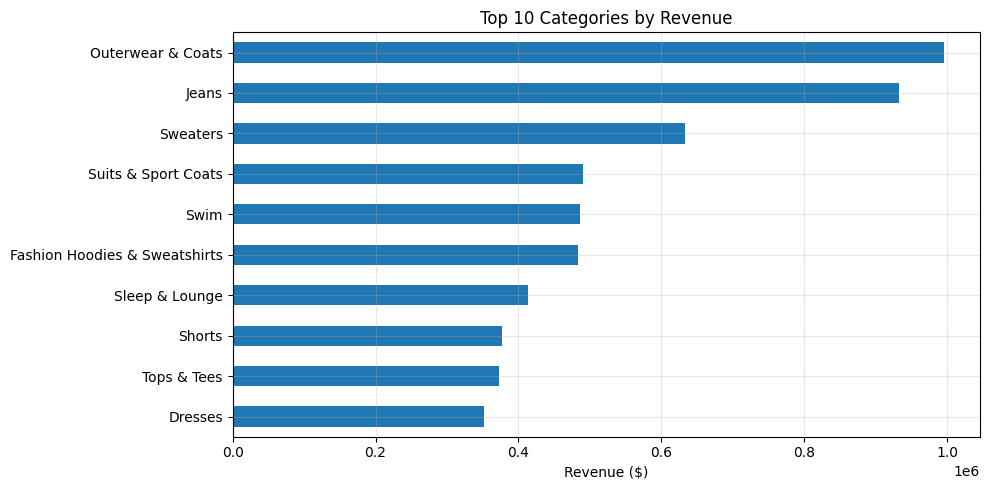

,category,revenue,units_sold
0,Outerwear & Coats,996036.25,6858
1,Jeans,933048.60,9450
2,Sweaters,633475.14,8438
3,Suits & Sport Coats,489947.18,3905
4,Swim,485846.22,8582
5,Fashion Hoodies & Sweatshirts,483096.62,8967
6,Sleep & Lounge,413625.76,8434
7,Shorts,376700.43,8244
8,Tops & Tees,372361.10,8984
9,Dresses,352148.00,4186


In [ ]:
CATEGORY_SQL = """
SELECT p.category,
       ROUND(SUM(oi.sale_price), 2) AS revenue,
       COUNT(*)                     AS units_sold
FROM `bigquery-public-data.thelook_ecommerce.order_items` AS oi
JOIN `bigquery-public-data.thelook_ecommerce.products`    AS p ON oi.product_id = p.id
WHERE oi.status NOT IN ('Cancelled', 'Returned')
GROUP BY p.category
ORDER BY revenue DESC
LIMIT 10
"""
cat = client.query(CATEGORY_SQL).to_dataframe()

ax = cat.sort_values("revenue").plot.barh(x="category", y="revenue", legend=False, figsize=(10, 5))
ax.set(title="Top 10 Categories by Revenue", xlabel="Revenue ($)", ylabel="")
plt.tight_layout(); plt.show()
cat

- **Revenue is concentrated.** Outerwear & Coats and Jeans together make up about a quarter of revenue, roughly \$1.93M of \$7.6M. The top 10 categories make up roughly 73%.

- **Outerwear wins on price, Jeans on volume.** Outerwear averages about \$145 per unit on 6,858 units, while Jeans averages about \$99 on 9,450 units. Suits & Sport Coats are similar to Outerwear at about \$125 per unit but sell only 3,905 units.

- **Swim, Hoodies, Sleep & Lounge, Shorts, and Tops & Tees** all sell 8,000–9,000 units but earn under \$60 each. They bring volume, not revenue.

## 11. Export results for the portfolio site

In [ ]:
cat["avg_price"] = (cat["revenue"] / cat["units_sold"]).round(2)
cat["revenue_share_%"] = (cat["revenue"] / revenue.sum() * 100).round(1)
cat

,category,revenue,units_sold,avg_price,revenue_share_%
0,Outerwear & Coats,996036.25,6858,145.24,13.1
1,Jeans,933048.60,9450,98.74,12.3
2,Sweaters,633475.14,8438,75.07,8.3
3,Suits & Sport Coats,489947.18,3905,125.47,6.4
4,Swim,485846.22,8582,56.61,6.4
5,Fashion Hoodies & Sweatshirts,483096.62,8967,53.87,6.4
6,Sleep & Lounge,413625.76,8434,49.04,5.4
7,Shorts,376700.43,8244,45.69,5.0
8,Tops & Tees,372361.10,8984,41.45,4.9
9,Dresses,352148.00,4186,84.13,4.6


In [ ]:
forecast_df.to_csv("revenue_forecast.csv")
scores.to_csv("model_comparison.csv")
print("Saved revenue_forecast.csv and model_comparison.csv")

Saved revenue_forecast.csv and model_comparison.csv
